# Лабораторная работа № 5. Разведочный анализ и проверка качества данных

**Проект:** поиск афиш по текстовому описанию. **Исполнитель:** Мирута Александр Владиславович, МИК22.  
**Данные:** синтетическая коллекция ЛР № 4, версия 1.1. **Дата:** 23.11.2026.

Цель — проверить предположения о составе и качестве данных перед обучением и определить, что может завысить оценку поиска. Выполните все ячейки сверху вниз. При запуске вне репозитория ноутбук загрузит данные по фиксированному коммиту GitHub. Для расчётов нужны Python 3.10+, pandas, matplotlib и CairoSVG с системной библиотекой Cairo. При необходимости установите библиотеки командой `%pip install pandas matplotlib cairosvg`. При выполнении сохраняется `quality_checks.csv` в текущей рабочей папке.

## Вопросы EDA и решения

| № | Вопрос | Как ответ повлияет на проект |
|---|---|---|
| 1 | Все ли жанры представлены во всех выборках? | При пробелах пересмотреть группировку или ограничить сравнение жанров. |
| 2 | Сбалансированы ли стили в каталоге и есть ли запросы к обоим стилям? | Оценивать каждый стиль только при наличии подходящих запросов. |
| 3 | Сколько групп и запросов в каждом split? Повторяется ли текст запроса между частями? | Разделять проверку на новых макетах и проверку на новых формулировках. |
| 4 | Какие дефекты есть в raw и объясняет ли журнал все исключения? | Зафиксировать правила очистки и использовать только допущенные карточки. |
| 5 | Согласованы ли размеры и форматы? Есть ли выбросы или связь характеристик файла со стилем? | Отправлять повреждённые файлы на проверку и исключать технические признаки из модели. |
| 6 | Выдают ли ID, цвет, семейство, описание или надписи жанр либо стиль? | Ограничить набор признаков и осторожно трактовать результат синтетического теста. |
| 7 | Есть ли пересечения авторов, серий и хешей, включая геометрию без надписей? | При пересечении пересобрать split и заново оценить модель на новой версии данных. |

## Загрузка и фиксация версии

In [1]:
from collections import Counter
from hashlib import sha256
from io import BytesIO
from itertools import combinations
from pathlib import Path
import csv
import json
import re
import unicodedata
from urllib.request import Request, urlopen
from xml.etree import ElementTree
from zipfile import ZipFile

from cairosvg import svg2png
from IPython.display import display
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

COMMIT = "00e7ca42ca5e38c91af5fbad18c1b262ef11586c"
SPLITS = ["train", "validation", "test"]
GENRES = ["джаз", "театр", "кино", "выставка", "электроника", "фестиваль"]
STYLES = ["минимализм", "детализация"]
local = next(
    (parent / "lab-04" for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / "lab-04/results/audit_summary.json").is_file()),
    None,
)

if local is None:
    url = f"https://codeload.github.com/LimeGoodGame/poster-search/zip/{COMMIT}"
    request = Request(url, headers={"User-Agent": "poster-search-lab05"})
    with urlopen(request, timeout=40) as response:
        archive = ZipFile(BytesIO(response.read()))
    archive_root = archive.namelist()[0].split("/")[0]
    print(f"Источник — GitHub, коммит {COMMIT[:7]}.")
else:
    print("Источник — файлы ЛР № 4 из локального репозитория.")

def read_bytes(relative_path):
    if local is not None:
        return (local / relative_path).read_bytes()
    return archive.read(f"{archive_root}/lab-04/{relative_path}")

def read_json(relative_path):
    return json.loads(read_bytes(relative_path))

def digest(payload):
    return sha256(payload).hexdigest()

manifest = read_json("results/audit_summary.json")
assert manifest["data_version"] == "1.1"
hash_mismatches = [
    name for name, expected in manifest["hashes"].items()
    if digest(read_bytes(name)) != expected
]

raw_rows = read_json("data/raw.json")
clean_rows = read_json("data/clean.json")
query_rows = read_json("data/queries.json")
journal = list(csv.DictReader(read_bytes("results/exclusions.csv").decode("utf-8").splitlines()))
# Cache the files once for the checks and previews below.
media_bytes = {path: read_bytes(path) for path in {row["image"] for row in raw_rows + clean_rows}}
if local is None:
    archive.close()

raw = pd.DataFrame(raw_rows)
clean = pd.DataFrame(clean_rows)
queries = pd.DataFrame(query_rows)
print(f"Версия данных {manifest['data_version']} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")
print(f"Raw: {len(raw)} · clean: {len(clean)} · запросы: {len(queries)}")

Источник — файлы ЛР № 4 из локального репозитория.
Версия данных 1.1 · pandas 3.1.1 · matplotlib 3.11.2
Raw: 42 · clean: 36 · запросы: 36


## Аудит схемы, медиа и разбиения

Сверяем манифест, поля карточек и запросов, размеры SVG и хеши самих файлов. Независимо повторяем правила очистки и сравниваем результат с журналом ЛР № 4. Точный хеш служит для проверки байтов, хеш SVG без надписей — для поиска повторения композиций в рамках генератора.

In [2]:
def words(value):
    normalized = unicodedata.normalize("NFKC", value).casefold()
    return re.findall(r"[а-яёa-z0-9]+", normalized)

def matches(value, pattern):
    return isinstance(value, str) and re.fullmatch(pattern, value) is not None

def card_valid(row):
    text_fields = [
        "id", "description", "genre", "style", "author", "series", "layout_family",
        "group_id", "split", "source", "rights_status", "data_version", "image", "sha256",
    ]
    return (
        all(isinstance(row.get(field), str) for field in text_fields)
        and matches(row["id"], r"[PDX][0-9]{3}")
        and row["genre"] in GENRES and row["style"] in STYLES
        and matches(row["author"], r"A0[1-6]") and matches(row["series"], r"S0[1-6]")
        and matches(row["layout_family"], r"L0[1-6]")
        and row["group_id"] == "|".join(row[field] for field in ["author", "series", "layout_family"])
        and row["split"] in SPLITS and row["source"] == "generated:prepare_data.py@1.1"
        and row["rights_status"] in {"demo_allowed", "unknown"}
        and row.get("synthetic") is True and row["data_version"] == "1.1"
        and all(type(row.get(field)) is int and row[field] > 0 for field in ["width", "height"])
        and matches(row["image"], r"data/posters/P[0-9]{3}\.svg")
        and matches(row["sha256"], r"[0-9a-f]{64}")
    )

def query_valid(row):
    return (
        matches(row.get("id"), r"(train|validation|test)_[0-9]{2}")
        and row.get("split") in SPLITS and row["id"].startswith(row["split"] + "_")
        and isinstance(row.get("text"), str) and bool(row["text"].strip())
        and row.get("genre") in GENRES and row.get("preferred_style") in STYLES
        and row.get("kind") in {"literal", "synonym"}
        and row.get("source") == "synthetic:prepare_data.py@1.1"
        and row.get("synthetic") is True
    )

SVG = "{http://www.w3.org/2000/svg}"

def inspect_svg(payload):
    root = ElementTree.fromstring(payload)
    if root.tag != SVG + "svg":
        raise ValueError("Корневой узел не SVG")
    width, height = (int(root.attrib[field]) for field in ["width", "height"])
    viewbox = tuple(map(float, root.attrib["viewBox"].split()))
    text_nodes = list(root.iter(SVG + "text"))
    text = " ".join("".join(node.itertext()) for node in text_nodes)
    colors = sorted({
        node.attrib[key].upper()
        for node in root.iter()
        for key in ["fill", "stroke"]
        if matches(node.get(key), r"#[0-9A-Fa-f]{6}") and node.attrib[key].upper() != "#FAF7F0"
    })
    normalized = re.sub(rb"<text\b[^>]*>.*?</text>", b"", payload, flags=re.DOTALL)
    return {
        "size": (width, height), "viewbox_ok": viewbox == (0, 0, width, height),
        "file_hash": digest(payload), "no_text_hash": digest(normalized),
        "bytes": len(payload), "svg_words": set(words(text)), "palette": tuple(colors),
    }

media = {}
bad_svg = []
for path, payload in media_bytes.items():
    try:
        media[path] = inspect_svg(payload)
    except (ElementTree.ParseError, ValueError, KeyError):
        bad_svg.append(path)

bad_media_metadata = [
    row["id"] for row in raw_rows + clean_rows
    if row["image"] in media and (
        media[row["image"]]["size"] != (row["width"], row["height"])
        or not media[row["image"]]["viewbox_ok"]
        or media[row["image"]]["file_hash"] != row["sha256"]
    )
]
bad_cards = sum(not card_valid(row) for row in raw_rows + clean_rows)
bad_queries = sum(not query_valid(row) for row in query_rows)

seen_hashes = set()
recreated_clean = []
recreated_journal = []
for row in raw_rows:
    if row["rights_status"] != "demo_allowed":
        reason = "unknown_rights"
    elif not row["description"].strip():
        reason = "empty_description"
    elif row["sha256"] in seen_hashes:
        reason = "duplicate_image"
    else:
        seen_hashes.add(row["sha256"])
        recreated_clean.append(row)
        continue
    recreated_journal.append({"id": row["id"], "reason": reason})

missing_raw = int(raw["description"].str.strip().eq("").sum())
missing_clean = int(clean["description"].str.strip().eq("").sum())
unknown_raw = int(raw["rights_status"].ne("demo_allowed").sum())
unknown_clean = int(clean["rights_status"].ne("demo_allowed").sum())
raw_hash_repeats = int(raw["sha256"].duplicated().sum())
clean_hash_repeats = int(clean["sha256"].duplicated().sum())
print("Причины из воспроизведённого журнала", dict(Counter(row["reason"] for row in recreated_journal)))

Причины из воспроизведённого журнала {'duplicate_image': 3, 'unknown_rights': 2, 'empty_description': 1}


In [3]:
assert not bad_svg and not bad_media_metadata, (bad_svg, bad_media_metadata)
assert not hash_mismatches and not bad_cards and not bad_queries

clean["svg_without_text"] = clean["image"].map(lambda path: media[path]["no_text_hash"])
clean["file_bytes"] = clean["image"].map(lambda path: media[path]["bytes"])
clean["dimensions"] = clean["image"].map(lambda path: "{} × {}".format(*media[path]["size"]))
queries["normalized_text"] = queries["text"].map(lambda value: " ".join(words(value)))

overlap_rows = []
query_overlap = pd.DataFrame(0, index=SPLITS, columns=SPLITS)
for first, second in combinations(SPLITS, 2):
    part_a = clean.loc[clean["split"].eq(first)]
    part_b = clean.loc[clean["split"].eq(second)]
    for field in ("id", "author", "series", "layout_family", "group_id", "sha256", "svg_without_text"):
        count = len(set(part_a[field]) & set(part_b[field]))
        overlap_rows.append({"Выборка 1": first, "Выборка 2": second, "Поле": field, "Пересечений": count})
    text_a = set(queries.loc[queries["split"].eq(first), "normalized_text"])
    text_b = set(queries.loc[queries["split"].eq(second), "normalized_text"])
    query_overlap.loc[first, second] = query_overlap.loc[second, first] = len(text_a & text_b)
for split in SPLITS:
    query_overlap.loc[split, split] = queries.loc[queries["split"].eq(split), "normalized_text"].nunique()
split_checks = pd.DataFrame(overlap_rows)

file_min = int(clean["file_bytes"].min())
file_max = int(clean["file_bytes"].max())
q1, q3 = clean["file_bytes"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = int((~clean["file_bytes"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum())

file_ids = clean["image"].map(lambda path: int(Path(path).stem[1:]))
clean["id_block"] = (file_ids - 1) // 6
clean["id_parity"] = file_ids % 2
clean["palette"] = clean["image"].map(lambda path: "/".join(media[path]["palette"]))
clean["size_range"] = pd.cut(clean["file_bytes"], bins=[float("-inf"), 434, float("inf")])
# Порог 434 взят как середина наблюдаемого разрыва между 407 и 461.
def purity(field, label):
    counts = pd.crosstab(clean[field], clean[label])
    return counts.max(axis=1).sum() / len(clean)

proxy_rows = [
    ("Цвет геометрии → жанр", purity("palette", "genre")),
    ("Блок ID → жанр", purity("id_block", "genre")),
    ("Чётность ID → стиль", purity("id_parity", "style")),
    ("Семейство → стиль", purity("layout_family", "style")),
    ("Интервал длины SVG → стиль", purity("size_range", "style")),
    ("Ширина и высота → стиль", purity("dimensions", "style")),
]
description_labels = {
    field: sum(row[field] in words(row["description"]) for row in clean_rows)
    for field in ["genre", "style"]
}
svg_labels = {
    field: sum(row[field] in media[row["image"]]["svg_words"] for row in clean_rows)
    for field in ["genre", "style"]
}
caption_texts = queries["normalized_text"].nunique()
print(f"Уникальных текстов запросов — {caption_texts} из {len(queries)} строк.")
print(f"Длина чистого SVG — {file_min}–{file_max} байта, выбросов по правилу 1,5 IQR — {outliers}.")
print("Явные метки в описании и SVG", description_labels, svg_labels)

Уникальных текстов запросов — 12 из 36 строк.
Длина чистого SVG — 378–532 байта, выбросов по правилу 1,5 IQR — 0.
Явные метки в описании и SVG {'genre': 36, 'style': 36} {'genre': 36, 'style': 36}


## Таблица качества

**Пройдено** означает соответствие зафиксированной схеме и протоколу. **Риск** указывает на особенности, которые остаются после очистки. Проверки файлов выполняются по SVG, а не по сохранённым значениям хеша из одной таблицы.

In [4]:
checks = []
def check(name, actual, criterion, passed, decision):
    checks.append({
        "Проверка": name, "Результат": str(actual), "Критерий": criterion,
        "Статус": "пройдено" if passed else "ошибка", "Решение": decision,
    })

check("Версия и целостность файлов", f"v1.1, {len(hash_mismatches)} расхождений из {len(manifest['hashes'])}",
      "Версия 1.1 и 0 расхождений", not hash_mismatches, "Использовать зафиксированный срез ЛР № 4.")
check("Объём raw / clean / запросы", f"{len(raw)} / {len(clean)} / {len(queries)}",
      "42 / 36 / 36", (len(raw), len(clean), len(queries)) == (42, 36, 36), "Зафиксировать размеры выборок.")
check("Схема карточек и запросов", f"{bad_cards} и {bad_queries} нарушений",
      "0 нарушений типов и допустимых значений", not (bad_cards or bad_queries), "Проверять схему до подготовки признаков.")
id_repeats = [int(frame["id"].duplicated().sum()) for frame in (raw, clean, queries)]
check("Повторные ID", " / ".join(map(str, id_repeats)),
      "0 / 0 / 0 в raw, clean и запросах", not any(id_repeats), "Связывать карточки и разметку по ID.")
check("Пустое описание в raw / clean", f"{missing_raw} / {missing_clean}", "1 / 0",
      (missing_raw, missing_clean) == (1, 0), "Исключить X003 из текстового поиска.")
check("Неизвестный допуск в raw / clean", f"{unknown_raw} / {unknown_clean}", "2 / 0",
      (unknown_raw, unknown_clean) == (2, 0), "Исключить X001 и X002 из каталога.")
check("Лишние строки по SHA-256 в raw / clean", f"{raw_hash_repeats} / {clean_hash_repeats}", "6 / 0",
      (raw_hash_repeats, clean_hash_repeats) == (6, 0), "Сохранить по одному допущенному объекту на хеш.")
check("Журнал и повтор очистки", f"{len(recreated_journal)} исключений, совпадение с clean и журналом",
      "6 исключений, полное совпадение", len(recreated_journal) == 6 and recreated_clean == clean_rows and recreated_journal == journal,
      "Сохранять причину исключения для каждой записи.")
check("Формат, размер и хеш SVG", f"{len(media)} SVG, {len(bad_svg) + len(bad_media_metadata)} расхождений",
      "36 валидных SVG, 0 расхождений", len(media) == 36 and not (bad_svg or bad_media_metadata),
      "Сверять viewBox, размеры и хеш с файлом.")
check("Покрытие жанров и стилей", "6 жанров × 2 и 2 стиля × 6 в split",
      "Все жанры и оба стиля в каждой части",
      all(Counter(part["genre"]) == dict.fromkeys(GENRES, 2)
          and Counter(part["style"]) == dict.fromkeys(STYLES, 6) for _, part in clean.groupby("split")),
      "Показывать результаты по жанрам и стилям запроса, если есть данные.")
split_counts = clean["split"].value_counts().reindex(SPLITS, fill_value=0)
query_counts = queries["split"].value_counts().reindex(SPLITS, fill_value=0)
group_counts = clean.groupby("split")["group_id"].nunique().reindex(SPLITS, fill_value=0)
check("Карточки, запросы и группы по split",
      ", ".join(f"{split} {split_counts[split]}/{query_counts[split]}/{group_counts[split]}" for split in SPLITS),
      "12 карточек, 12 запросов и 2 группы в каждой части",
      split_counts.eq(12).all() and query_counts.eq(12).all() and group_counts.eq(2).all(),
      "Сохранить каталоги и группы выборок.")
check("Выбросы по длине SVG", f"{outliers} за границами 1,5 IQR, диапазон {file_min}–{file_max} байта",
      "0 выбросов для данного среза", outliers == 0, "Длину файла рассматривать как свойство генератора.")
check("Группы и хеши между split", f"{len(split_checks)} попарная проверка, сумма пересечений {split_checks['Пересечений'].sum()}",
      "21 проверка, 0 пересечений", len(split_checks) == 21 and split_checks["Пересечений"].eq(0).all(),
      "Сохранять целые группы и сверять хеш после удаления надписей.")

checks.extend([
    {"Проверка": "Независимость текстов запросов", "Результат": f"{caption_texts} уникальных текстов из {len(queries)} строк",
     "Критерий": "Для оценки новых текстов нужны отдельные формулировки", "Статус": "риск",
     "Решение": "Текущий test использовать для технической проверки на других карточках."},
    {"Проверка": "Покрытие стилей запросами",
     "Результат": f"{queries['preferred_style'].eq('минимализм').sum()} запросов на минимализм, {queries['preferred_style'].eq('детализация').sum()} на детализацию",
     "Критерий": "Для сравнения стилей нужны запросы на каждый стиль", "Статус": "риск",
     "Решение": "Добавить независимые запросы на детализацию в следующий набор."},
    {"Проверка": "Признаки, раскрывающие метки",
     "Результат": f"Цвет → жанр {purity('palette', 'genre'):.0%}. Чётность ID → стиль {purity('id_parity', 'style'):.0%}",
     "Критерий": "Признаки генератора не входят в модель", "Статус": "риск",
     "Решение": "Для TF-IDF передавать только description и текст запроса, ограничить выводы."},
])

quality = pd.DataFrame(checks)
display(quality)
display(split_checks.pivot(index="Поле", columns=["Выборка 1", "Выборка 2"], values="Пересечений"))
quality.to_csv("quality_checks.csv", index=False, encoding="utf-8")
assert not quality["Статус"].eq("ошибка").any()

,Проверка,Результат,Критерий,Статус,Решение
0,Версия и целостность файлов,"v1.1, 0 расхождений из 41",Версия 1.1 и 0 расхождений,пройдено,Использовать зафиксированный срез ЛР № 4.
1,Объём raw / clean / запросы,42 / 36 / 36,42 / 36 / 36,пройдено,Зафиксировать размеры выборок.
2,Схема карточек и запросов,0 и 0 нарушений,0 нарушений типов и допустимых значений,пройдено,Проверять схему до подготовки признаков.
3,Повторные ID,0 / 0 / 0,"0 / 0 / 0 в raw, clean и запросах",пройдено,Связывать карточки и разметку по ID.
4,Пустое описание в raw / clean,1 / 0,1 / 0,пройдено,Исключить X003 из текстового поиска.
5,Неизвестный допуск в raw / clean,2 / 0,2 / 0,пройдено,Исключить X001 и X002 из каталога.
6,Лишние строки по SHA-256 в raw / clean,6 / 0,6 / 0,пройдено,Сохранить по одному допущенному объекту на хеш.
7,Журнал и повтор очистки,"6 исключений, совпадение с clean и журналом","6 исключений, полное совпадение",пройдено,Сохранять причину исключения для каждой записи.
8,"Формат, размер и хеш SVG","36 SVG, 0 расхождений","36 валидных SVG, 0 расхождений",пройдено,"Сверять viewBox, размеры и хеш с файлом."
9,Покрытие жанров и стилей,6 жанров × 2 и 2 стиля × 6 в split,Все жанры и оба стиля в каждой части,пройдено,Показывать результаты по жанрам и стилям запро...


Выборка 1             train      validation
Выборка 2        validation test       test
Поле                                       
author                    0    0          0
group_id                  0    0          0
id                        0    0          0
layout_family             0    0          0
series                    0    0          0
sha256                    0    0          0
svg_without_text          0    0          0

## Шесть графиков и решения

В графиках указаны выборка и единица счёта. Три проверки с предупреждениями в таблице относятся к содержанию синтетического набора и возможности переноса на новые данные.

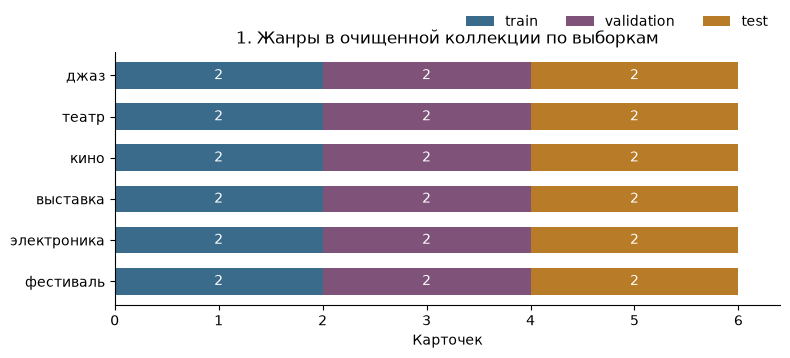

In [5]:
import numpy as np

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#3B6B8A", "#7F5279", "#B87B27"]

def label_bars(ax):
    for container in ax.containers:
        ax.bar_label(container, fmt="%g", padding=3)

def finish(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

genre_split = pd.crosstab(clean["genre"], clean["split"]).reindex(index=GENRES, columns=SPLITS)
fig, ax = plt.subplots(figsize=(8, 3.7))
genre_split.iloc[::-1].plot.barh(stacked=True, color=COLORS, ax=ax, width=0.65)
ax.set(xlabel="Карточек", ylabel=None, title="1. Жанры в очищенной коллекции по выборкам", xlim=(0, 6.4))
ax.legend(title=None, loc="lower right", bbox_to_anchor=(1, 1.04), ncol=3, frameon=False)
for bars in ax.containers:
    ax.bar_label(bars, label_type="center", color="white")
finish(fig)

**График 1.** В каждом split по две карточки каждого жанра. Для этой технической проверки менять веса жанров по частоте не требуется. Баланс задан генератором, поэтому частоты жанров реального архива нужно измерить отдельно.

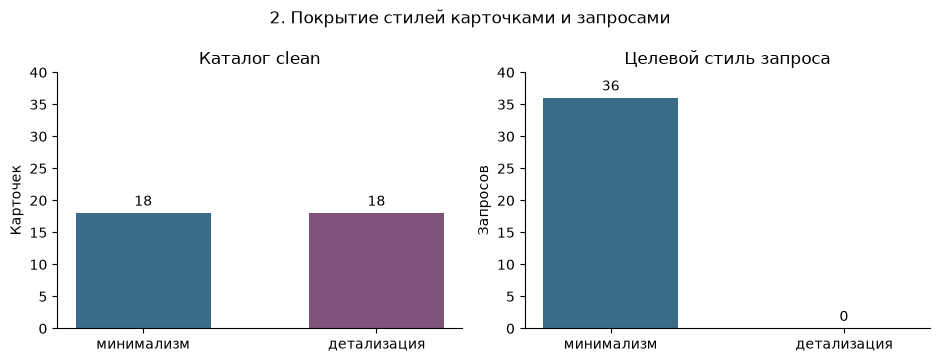

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.65))
for ax, frame, column, title, unit in [
    (axes[0], clean, "style", "Каталог clean", "Карточек"),
    (axes[1], queries, "preferred_style", "Целевой стиль запроса", "Запросов"),
]:
    counts = frame[column].value_counts().reindex(STYLES, fill_value=0)
    ax.bar(counts.index, counts, color=COLORS[:2], width=0.58)
    ax.set(title=title, ylabel=unit, ylim=(0, 40))
    label_bars(ax)
fig.suptitle("2. Покрытие стилей карточками и запросами")
finish(fig)

**График 2.** В каталоге по 18 карточек обоих стилей, но все запросы направлены на минимализм. У оценки поиска детализации пока нет целевых запросов. Для следующего эксперимента нужно включить этот сценарий.

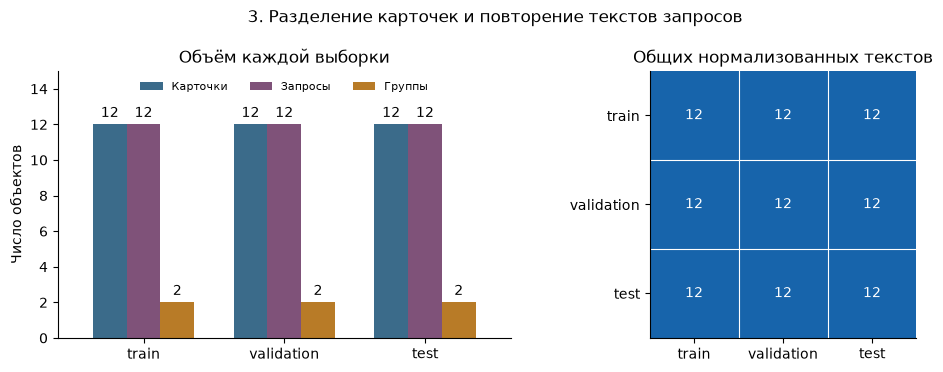

In [7]:
coverage = pd.DataFrame({
    "Карточки": split_counts,
    "Запросы": query_counts,
    "Группы": group_counts,
})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.75), gridspec_kw={"width_ratios": [1.15, 1]})
coverage.plot.bar(color=COLORS, ax=axes[0], width=0.72)
axes[0].set(title="Объём каждой выборки", ylabel="Число объектов", xlabel=None, ylim=(0, 15))
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(frameon=False, ncol=3, fontsize=8, loc="upper center")
label_bars(axes[0])
axes[1].imshow(query_overlap.to_numpy(), cmap="Blues", vmin=0, vmax=15)
for i, first in enumerate(SPLITS):
    for j, second in enumerate(SPLITS):
        axes[1].text(j, i, query_overlap.loc[first, second], ha="center", va="center", color="white")
axes[1].set(xticks=range(3), xticklabels=SPLITS, yticks=range(3), yticklabels=SPLITS,
            title="Общих нормализованных текстов")
axes[1].set_xticks([0.5, 1.5], minor=True)
axes[1].set_yticks([0.5, 1.5], minor=True)
axes[1].grid(which="minor", color="white", linewidth=0.8)
axes[1].tick_params(which="minor", bottom=False, left=False)
fig.suptitle("3. Разделение карточек и повторение текстов запросов")
finish(fig)

**График 3.** В каждой части по две группы, 12 карточек и 12 запросов. По всем парам выборок совпадают все 12 текстов запросов. Нулевое пересечение групп позволяет проверить работу на других макетах. Для оценки новых формулировок понадобится отдельный тест с разделением по смысловым группам запросов.

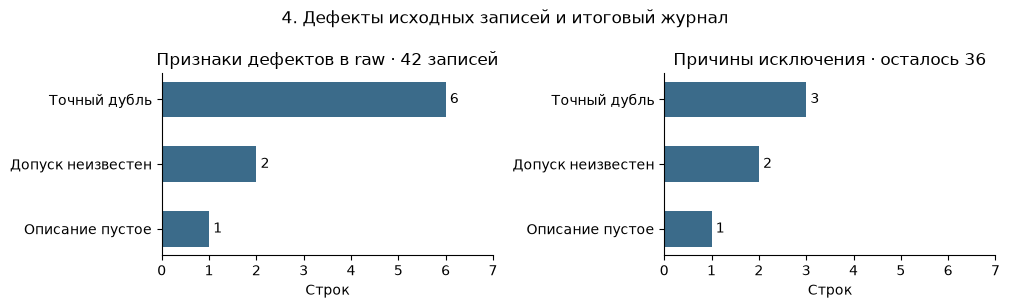

In [8]:
reason_order = ["duplicate_image", "unknown_rights", "empty_description"]
reason_names = ["Точный дубль", "Допуск неизвестен", "Описание пустое"]
counts = Counter(row["reason"] for row in recreated_journal)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.1), sharex=True)
for ax, values, title in [
    (axes[0], [raw_hash_repeats, unknown_raw, missing_raw], f"Признаки дефектов в raw · {len(raw)} записей"),
    (axes[1], [counts[key] for key in reason_order], f"Причины исключения · осталось {len(clean)}"),
]:
    bars = ax.barh(reason_names[::-1], values[::-1], color=COLORS[0], height=0.55)
    ax.bar_label(bars, padding=3)
    ax.set(xlabel="Строк", title=title, xlim=(0, 7))
fig.suptitle("4. Дефекты исходных записей и итоговый журнал")
finish(fig)

**График 4.** Шесть строк сверх уникальных хешей в raw включают строки с другими дефектами. Приоритет проверки — допуск, описание, затем хеш. Поэтому в журнале по хешу исключены три записи, по допуску две, по пустому описанию одна. У каждой исключённой строки одна причина, и 42 − 6 = 36.

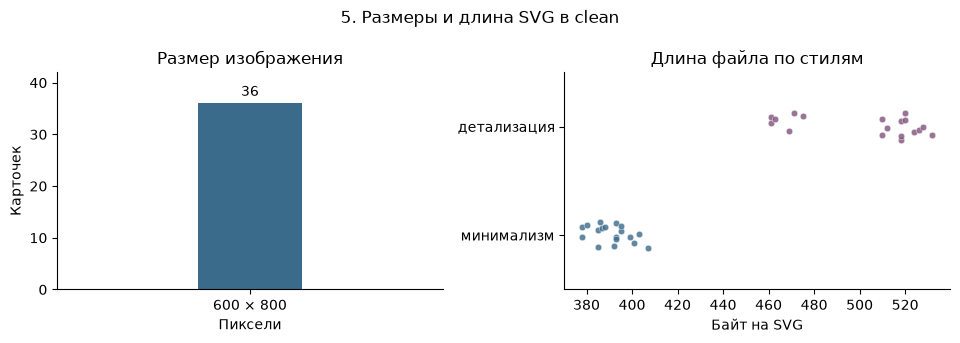

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.7, 3.45))
size_counts = clean["dimensions"].value_counts()
axes[0].bar(size_counts.index, size_counts, color=COLORS[0], width=0.38)
axes[0].set(title="Размер изображения", ylabel="Карточек", xlabel="Пиксели", ylim=(0, 42), xlim=(-0.7, 0.7))
label_bars(axes[0])
rng = np.random.default_rng(42)
for i, name in enumerate(STYLES):
    values = clean.loc[clean["style"].eq(name), "file_bytes"].sort_values().to_numpy()
    offsets = rng.uniform(-0.13, 0.13, len(values))
    axes[1].scatter(values, i + offsets, color=COLORS[i], s=22, alpha=0.8, edgecolors="white", linewidths=0.35)
axes[1].set(yticks=range(len(STYLES)), yticklabels=STYLES, ylim=(-0.5, 1.5),
            title="Длина файла по стилям", xlabel="Байт на SVG")
fig.suptitle("5. Размеры и длина SVG в clean")
finish(fig)

**График 5.** У всех 36 SVG размер 600 × 800, поэтому ориентация не различает стили в версии 1.1. При этом длина файла различает их в текущем наборе. У минимализма 378–407 байт, у детализации 461–532 байта. Выбросов по правилу 1,5 IQR нет. Длина зависит от оформления SVG и исключается из признаков.

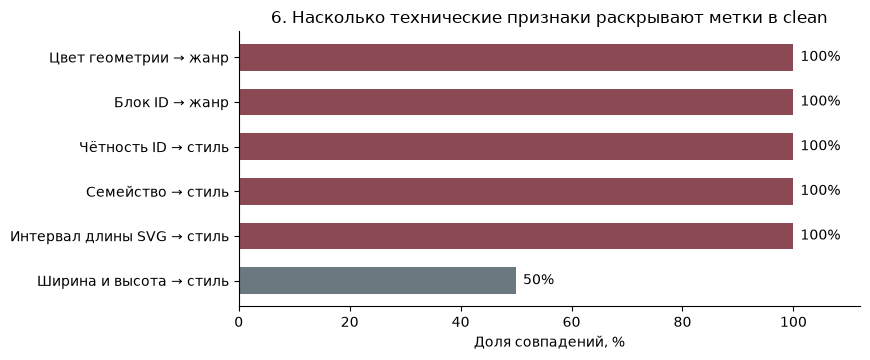

In [10]:
names = [name for name, value in reversed(proxy_rows)]
percent = [100 * value for name, value in reversed(proxy_rows)]
fig, ax = plt.subplots(figsize=(8.8, 3.7))
bars = ax.barh(names, percent, color=["#6B7880" if value < 100 else "#8B4A53" for value in percent], height=0.6)
ax.bar_label(bars, labels=[f"{value:.0f}%" for value in percent], padding=5)
ax.set(xlim=(0, 112), xlabel="Доля совпадений, %", title="6. Насколько технические признаки раскрывают метки в clean")
finish(fig)

**График 6.** Для каждого признака карточке присвоена самая частая метка среди карточек с тем же значением признака. Доля совпадений рассчитана по тем же 36 карточкам. Это проверка связи в наборе, а порог длины SVG выбран после просмотра, поэтому значения нельзя считать качеством модели на новых данных. Файл назван по ID. Блок числовых ID и цвет совпадают с жанром, а чётность ID и семейство — со стилем. Слово жанра и слово стиля присутствуют в описании и в SVG у каждой clean-карточки. Посторонних признаков TF-IDF не получает, но из-за шаблонных описаний задача в этом каталоге проще реальной.

## Просмотр типичных и проблемных афиш

Используем SVG из поля `image` исходной карточки и показываем их в одинаковом масштабе. В нижнем ряду контрольные дефекты относятся к метаданным и повторению файлов. На самих изображениях намеренно нет повреждений.

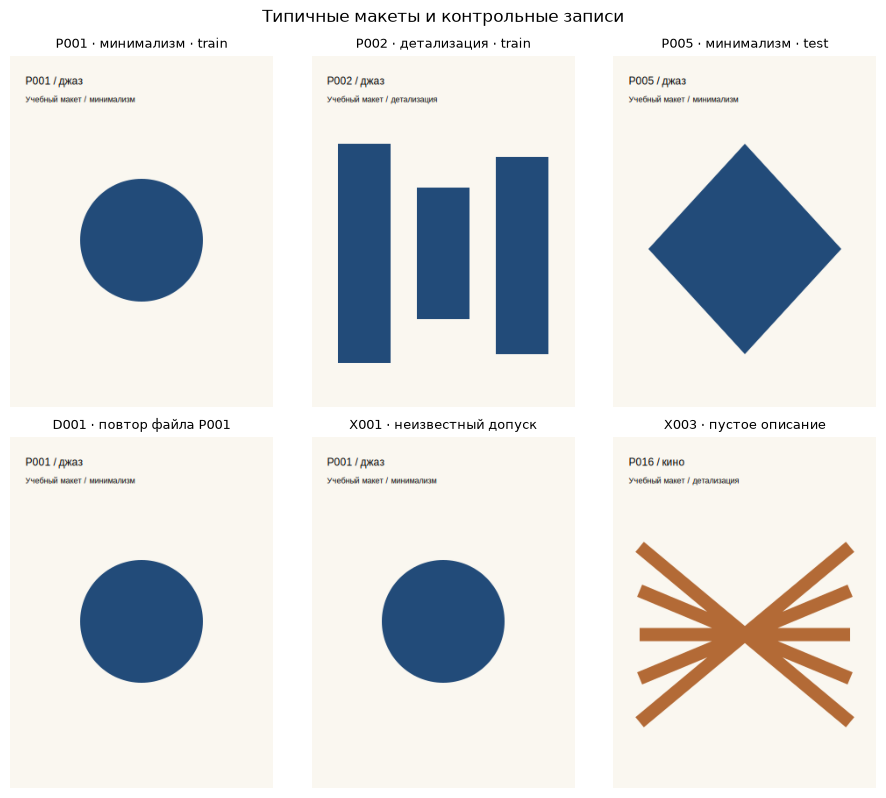

,ID,Файл,Начало SHA-256,Допуск,Описание,Итог
0,P001,P001.svg,ec35bfa07b23,demo_allowed,джаз афиша минимализм геометрия круг,оставлена
1,P002,P002.svg,7b826f324916,demo_allowed,джаз афиша детализация геометрия прямоугольники,оставлена
2,P005,P005.svg,4233f6c31189,demo_allowed,джаз афиша минимализм геометрия ромб,оставлена
3,D001,P001.svg,ec35bfa07b23,demo_allowed,джаз афиша минимализм геометрия круг,duplicate_image
4,X001,P001.svg,ec35bfa07b23,unknown,джаз афиша минимализм геометрия круг,unknown_rights
5,X003,P016.svg,506a1cd66f78,demo_allowed,пусто,empty_description


In [11]:
examples = [
    ("P001", "минимализм · train"), ("P002", "детализация · train"), ("P005", "минимализм · test"),
    ("D001", "повтор файла P001"), ("X001", "неизвестный допуск"), ("X003", "пустое описание"),
]
by_id = {row["id"]: row for row in raw_rows}
fig, axes = plt.subplots(2, 3, figsize=(9.2, 8.1))
preview = []
reason_by_id = {row["id"]: row["reason"] for row in journal}
for ax, (identifier, label) in zip(axes.flat, examples):
    row = by_id[identifier]
    png = svg2png(bytestring=media_bytes[row["image"]], output_width=300, output_height=400)
    ax.imshow(plt.imread(BytesIO(png), format="png"))
    ax.set_title(f"{identifier} · {label}", fontsize=9)
    ax.axis("off")
    preview.append({
        "ID": identifier, "Файл": Path(row["image"]).name,
        "Начало SHA-256": row["sha256"][:12], "Допуск": row["rights_status"],
        "Описание": row["description"] or "пусто",
        "Итог": reason_by_id.get(identifier, "оставлена"),
    })
fig.suptitle("Типичные макеты и контрольные записи")
finish(fig)
display(pd.DataFrame(preview))
assert by_id["D001"]["sha256"] == by_id["P001"]["sha256"]
assert by_id["X001"]["rights_status"] == "unknown" and not by_id["X003"]["description"].strip()

P001 и P002 относятся к одному жанру. У первого круг, у второго три прямоугольника. P005 показывает, что в тесте используется другой геометрический шаблон. В карточке D001 открыт тот же файл, что у P001. X001 тоже ссылается на него, но исключён раньше из-за допуска. У X003 есть читаемое изображение с маркировкой P016, а поле описания пустое. Ни один из этих случаев не требует запуска ранжировщика, чтобы объяснить, почему запись исключена.

## Data Card после аудита


**Паспорт обновлён 23.11.2026 после ЛР № 5. Версия данных остаётся 1.1.** Ответственный — Мирута Александр Владиславович, МИК22. Назначение набора — проверка подготовки данных, ранжирования по тексту и расчёта метрик на синтетическом каталоге. Происхождение, условия использования и версия генератора указаны в [реестре ЛР № 4](../lab-04/sources.md). Протокол с фактическими значениями находится в [таблице качества](quality_checks.csv).

**Состав и обработка.** Из 42 исходных строк оставлены 36 карточек. Журнал фиксирует три дубликата, два неизвестных допуска и одно пустое описание. Все 36 SVG имеют размер 600 × 800. Шесть жанров представлены по шесть раз, два стиля — по 18. В каждом из train, validation и test по две вымышленные авторские группы, 12 карточек и 12 запросов. Все описания и запросы русскоязычные, изображения и запросы имеют `synthetic=true`. Персональных данных в коллекции нет. Статус `demo_allowed` обозначает допуск к учебной выдаче. Для подключения реального архива требуется подтверждение условий использования.

**Проверки ЛР № 5.** В clean нет пропусков обязательных полей, повторных ID и хешей, сомнительных допусков и расхождений между SVG и метаданными. Пересечения авторов, серий, семейств и хешей между выборками отсутствуют, включая сверку файлов после удаления надписей. Размеры SVG соответствуют схеме. Длина файла составляет 378–532 байта, выбросов по правилу 1,5 межквартильного размаха нет. На контрольных примерах показаны нормальные афиши, точный дубль, неизвестный допуск и пустое описание.

**Ограничения оценки.** Во всех выборках повторяются одни и те же 12 нормализованных текстов запроса. Все 36 запросов ищут минимализм, поэтому качество поиска детализации по этим запросам измерить нельзя. Цвет геометрии и диапазон числовых ID совпадают с жанром, чётность ID, семейство и диапазон длины файла совпадают со стилем. Размер в пикселях одинаков для всех макетов. Жанр и стиль явно названы в описании и надписях SVG. Результаты отражают поиск по шаблонным описаниям, в которых метки доступны как слова. Для проверки естественных формулировок, новых авторов и реальных изображений нужен отдельный материал.

**Решение для следующих этапов.** Разрешённый вход TF-IDF — `description` и текст запроса. Идентификаторы, пути, цвета, размеры, длину файлов, группы и явные поля `genre` и `style` оставить для аудита и разметки. Словарь признаков и IDF вычислять по train. Текущий test использовать как техническую проверку на отдельных макетах. Для проверки новых запросов заранее собрать независимый набор формулировок по обоим стилям, сгруппировать одинаковые и близкие запросы и скрыть итоговый тест до фиксации модели. На ЛР № 6 провести пилот инструкции и проверить согласие по разметке. После изменения состава, схемы или разметки обновить версию и повторить аудит.

## Источники

- Методические указания «МУ_ЛР_05» и демонстрационные материалы ЛР № 5. [Репозиторий курса](https://github.com/Irina-64/ml-creative-technologies-course/tree/main/labs/05)
- Набор ЛР № 4 версии 1.1 и исходный паспорт. [Фиксированный срез](https://github.com/LimeGoodGame/poster-search/tree/00e7ca42ca5e38c91af5fbad18c1b262ef11586c/lab-04)